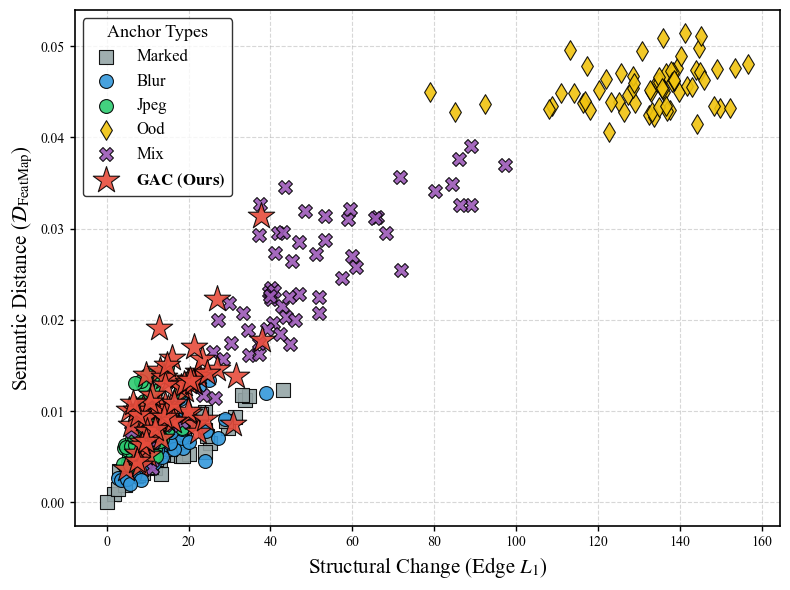

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman"],  
    "mathtext.fontset": "stix",         
    "axes.linewidth": 1.2,              
    "xtick.major.width": 1.0,
    "ytick.major.width": 1.0,
    "pdf.fonttype": 42,                
    "ps.fonttype": 42
})

df = pd.read_csv('results/annotation_cleaner/metrics_details.csv')

fig, ax = plt.subplots(figsize=(8, 6))

palette = {'blur': '#3498db', 'jpeg': '#2ecc71', 'marked': '#95a5a6', 
           'mix': '#9b59b6', 'ood': '#f1c40f', 'gac': '#e74c3c'}
markers = {'blur': 'o', 'jpeg': 'o', 'marked': 's', 'mix': 'X', 'ood': 'd', 'gac': '*'}

anchors_order = ['marked', 'blur', 'jpeg', 'ood', 'mix', 'gac']

for anchor in anchors_order:
    subset = df[df['Anchor'] == anchor]
    label_text = r'$\mathbf{GAC \ (Ours)}$' if anchor == 'gac' else anchor.capitalize()
    
    ax.scatter(
        subset['Edge_L1'], subset['D_FeatMap'],
        c=palette[anchor], 
        label=label_text,
        marker=markers[anchor],
        s=400 if anchor == 'gac' else 100,
        edgecolors='black',
        linewidth=0.8,
        alpha=0.9,
        zorder=5 if anchor == 'gac' else 3
    )

ax.set_xlabel(r'Structural Change ($\text{Edge } L_1$)', fontsize=15)
ax.set_ylabel(r'Semantic Distance ($\mathcal{D}_{\text{FeatMap}}$)', fontsize=15)

legend = ax.legend(title='Anchor Types', fontsize=12, title_fontsize=13, 
                   loc='best', frameon=True, edgecolor='black')
legend.get_frame().set_linewidth(1.0)

ax.grid(True, linestyle='--', alpha=0.5, zorder=0)
plt.tight_layout()
plt.savefig('results/annotation_cleaner/Figure 4.pdf', format='pdf', bbox_inches='tight')
plt.show()